# 04 · Modelul de vulnerabilitate (LightGBM + SHAP)
Explică pierderea observată în 2024 (ținta din `03e`) prin factori structurali, doar pe parcelele arabile. Validare pe blocuri spațiale de 5 km, explicații cu SHAP pe fiecare parcelă.

Rezultatul arată **asocieri, nu cauze dovedite**. Harta-erou arată pierderea observată; scorul de aici e panou secundar, cu R² spațial scris pe slide.

In [1]:
# Sincronizare: aduce repo-ul pe runtime și încarcă configurarea.
# Local (kernel pe PC) găsește direct ../gisday_config.py; pe Colab clonează repo-ul privat.
import os, sys, subprocess, base64, getpass

def _auth(tok):
    b = base64.b64encode(f'x-access-token:{tok}'.encode()).decode()
    return ['-c', f'http.extraheader=AUTHORIZATION: basic {b}']

def _token():
    global TOKEN
    if 'TOKEN' not in globals():
        TOKEN = getpass.getpass('Token GitHub (fine-grained, doar repo-ul gisday2026): ')
    return TOKEN

if not os.path.exists('gisday_config.py'):
    if os.path.exists('../gisday_config.py'):
        os.chdir('..')
    else:
        REPO = 'https://github.com/lefterpatrickandrei-sketch/gisday2026.git'   # același cu GITHUB_REPO din gisday_config.py
        if not os.path.exists('/content/gisday2026'):
            subprocess.run(['git', *_auth(_token()), 'clone', REPO, '/content/gisday2026'], check=True)
        os.chdir('/content/gisday2026')
sys.path.insert(0, os.getcwd())
from gisday_config import *

def pull():
    subprocess.run(['git', *_auth(_token()), 'pull', '--ff-only'], check=True)

def push(paths, msg):
    subprocess.run(['git', 'add', *[str(p) for p in paths]], check=True)
    subprocess.run(['git', '-c', 'user.name=gisday-runtime', '-c', 'user.email=gisday@users.noreply.github.com',
                    'commit', '-m', msg], check=False)
    subprocess.run(['git', *_auth(_token()), 'push'], check=True)

print('Lucrez în', os.getcwd())

Lucrez în C:\Users\lefpa\Downloads\gisday2026\gisday2026


In [2]:
%pip install -q lightgbm shap geopandas pyarrow matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import geopandas as gpd, pandas as pd, numpy as np, lightgbm as lgb, shap, json
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error
parcels = gpd.read_parquet(OUT / 'parcels.parquet')
F = pd.read_parquet(OUT / 'parcel_features.parquet')
T = pd.read_parquet(OUT / 'parcel_target.parquet')          # ținta din 03e: loss_rel like-for-like HR-VPP TPROD
D = parcels.merge(F, on='parcel_id').merge(T, on='parcel_id')
for name in ('parcel_canals', 'parcel_wind'):               # factorii din 03f și 03c
    if (OUT / f'{name}.parquet').exists():
        D = D.merge(pd.read_parquet(OUT / f'{name}.parquet'), on='parcel_id')
TARGET = D.loss_source.iloc[0]
D = D[D.is_arable].copy()                                   # toate parcelele arabile
D['tip_cultura_2024_num'] = D['tip_cultura_2024'].map({'primavara': 0, 'neclasificat': 1, 'toamna': 2})
print(f"ținta: {TARGET} | parcele arabile: {len(D)} | cu țintă: {int(D['loss'].notna().sum())}")
print(D['loss'].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(4).to_string())

C:\Users\lefpa\Downloads\gisday2026\gisday2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ținta: hrvpp_tprod_lfl_rel | parcele arabile: 13237 | cu țintă: 11971
count    11971.0000
mean         0.0524
std          0.4895
min         -1.7634
1%          -1.7615
5%          -0.8895
25%         -0.1756
50%          0.1474
75%          0.3993
95%          0.6545
99%          0.7629
max          0.7629


In [4]:
# Factori structurali permiși (PAS C1–C2): nimic din vara 2024 și fără irrigated_prob în modelul principal.
CANDIDATES = ['elev', 'slope', 'soc_sg_top', 'sand_sg_top', 'clay_sg_top', 'soc_lucas_model',
              'wind_exposure', 'dist_canal_m', 'dist_network_m', 'area_ha',
              'tip_cultura_2024_num', 'tprod_mean_2017_2023']
FEATURES = [c for c in CANDIDATES if c in D.columns]
STRUCTURAL_FEATURES = [c for c in FEATURES if c != 'tip_cultura_2024_num']
print('factori:', FEATURES)
D = D.dropna(subset=FEATURES).copy()
D['are_tinta'] = np.where(D['loss'].notna(), 'da', 'nu')
c = D.geometry.centroid
D['block'] = (c.x // 5000).astype(int).astype(str) + '_' + (c.y // 5000).astype(int).astype(str)
TR = D[D['are_tinta'] == 'da'].copy()
X, y = TR[FEATURES], TR['loss']
print(f"parcele arabile pentru predicție: {len(D)} (are_tinta='da': {len(TR)}, 'nu': {len(D) - len(TR)}) | blocuri de 5 km: {TR['block'].nunique()}")

factori: ['elev', 'slope', 'soc_sg_top', 'sand_sg_top', 'clay_sg_top', 'wind_exposure', 'dist_canal_m', 'dist_network_m', 'area_ha', 'tip_cultura_2024_num', 'tprod_mean_2017_2023']
parcele arabile pentru predicție: 13230 (are_tinta='da': 11965, 'nu': 1265) | blocuri de 5 km: 82


In [5]:
params = dict(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=30,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=2024, verbose=-1)
pred = np.zeros(len(TR))
pred_base = np.zeros(len(TR))
pred_base_grp = np.zeros(len(TR))
fold_r2, fold_rmse = [], []
for k, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, y, TR['block'])):
    m = lgb.LGBMRegressor(**params).fit(X.iloc[tr], y.iloc[tr])
    pred[te] = m.predict(X.iloc[te])
    pred_base[te] = y.iloc[tr].mean()
    for g in ('toamna', 'primavara'):
        m_tr = (TR['tip_cultura_2024'].iloc[tr] == g).values
        m_te = (TR['tip_cultura_2024'].iloc[te] == g).values
        if m_te.sum() > 0:
            pred_base_grp[te[m_te]] = y.iloc[tr][m_tr].mean()
    r2_k = float(r2_score(y.iloc[te], pred[te]))
    rmse_k = float(mean_squared_error(y.iloc[te], pred[te]) ** 0.5)
    fold_r2.append(round(r2_k, 4)); fold_rmse.append(round(rmse_k, 4))
    print(f'fold {k}: R2={r2_k:.4f}, RMSE={rmse_k:.4f}')
r2_by_group = {g: round(float(r2_score(y[TR.tip_cultura_2024 == g], pred[TR.tip_cultura_2024 == g])), 4)
               for g in ('toamna', 'primavara') if (TR.tip_cultura_2024 == g).sum() > 10}
rmse_by_group = {g: round(float(mean_squared_error(y[TR.tip_cultura_2024 == g], pred[TR.tip_cultura_2024 == g]) ** 0.5), 4)
                 for g in ('toamna', 'primavara') if (TR.tip_cultura_2024 == g).sum() > 10}
r2_base_by_group = {g: round(float(r2_score(y[TR.tip_cultura_2024 == g], pred_base_grp[TR.tip_cultura_2024 == g])), 4)
                    for g in ('toamna', 'primavara') if (TR.tip_cultura_2024 == g).sum() > 10}
rmse_base_by_group = {g: round(float(mean_squared_error(y[TR.tip_cultura_2024 == g], pred_base_grp[TR.tip_cultura_2024 == g]) ** 0.5), 4)
                      for g in ('toamna', 'primavara') if (TR.tip_cultura_2024 == g).sum() > 10}
metrics = dict(target=TARGET, r2_spatial=round(float(r2_score(y, pred)), 4),
               r2_folds_mean=round(float(np.mean(fold_r2)), 4), fold_r2=fold_r2,
               rmse=round(float(mean_squared_error(y, pred) ** 0.5), 4),
               rmse_folds_mean=round(float(np.mean(fold_rmse)), 4), fold_rmse=fold_rmse,
               r2_baseline_mean=round(float(r2_score(y, pred_base)), 4),
               rmse_baseline_mean=round(float(mean_squared_error(y, pred_base) ** 0.5), 4),
               r2_by_group=r2_by_group, rmse_by_group=rmse_by_group,
               r2_baseline_by_group=r2_base_by_group, rmse_baseline_by_group=rmse_base_by_group,
               n_parcels_train=len(TR), n_parcels_pred=len(D),
               n_blocks=int(TR['block'].nunique()), factors=FEATURES)
print('validare spațială:', metrics)
(OUT / 'model_metrics.json').write_text(json.dumps(metrics, indent=1), encoding='utf-8')

fold 0: R2=0.0493, RMSE=0.4527


fold 1: R2=0.1090, RMSE=0.4379


fold 2: R2=0.1267, RMSE=0.4587


fold 3: R2=0.1079, RMSE=0.4818


fold 4: R2=0.0350, RMSE=0.5060
validare spațială: {'target': 'hrvpp_tprod_lfl_rel', 'r2_spatial': 0.086, 'r2_folds_mean': 0.0856, 'fold_r2': [0.0493, 0.109, 0.1267, 0.1079, 0.035], 'rmse': 0.468, 'rmse_folds_mean': 0.4674, 'fold_rmse': [0.4527, 0.4379, 0.4587, 0.4818, 0.506], 'r2_baseline_mean': -0.0005, 'rmse_baseline_mean': 0.4897, 'r2_by_group': {'toamna': 0.0058, 'primavara': 0.0033}, 'rmse_by_group': {'toamna': 0.4899, 'primavara': 0.438}, 'r2_baseline_by_group': {'toamna': -0.0021, 'primavara': -0.0049}, 'rmse_baseline_by_group': {'toamna': 0.4918, 'primavara': 0.4398}, 'n_parcels_train': 11965, 'n_parcels_pred': 13230, 'n_blocks': 82, 'factors': ['elev', 'slope', 'soc_sg_top', 'sand_sg_top', 'clay_sg_top', 'wind_exposure', 'dist_canal_m', 'dist_network_m', 'area_ha', 'tip_cultura_2024_num', 'tprod_mean_2017_2023']}


881

In [6]:
model = lgb.LGBMRegressor(**params).fit(X, y)
sv = shap.TreeExplainer(model).shap_values(D[FEATURES])
S = pd.DataFrame(sv, columns=[f'shap_{f}' for f in FEATURES], index=D.index)
S_struct = S[[f'shap_{f}' for f in STRUCTURAL_FEATURES]]
D['id'] = D['parcel_id']
loss_pred_all = pd.Series(index=D.index, dtype=float)
loss_pred_all.loc[TR.index] = pred
no_tinta_idx = D.index[D['are_tinta'] == 'nu']
if len(no_tinta_idx) > 0:
    loss_pred_all.loc[no_tinta_idx] = model.predict(D.loc[no_tinta_idx, FEATURES])
D['loss_pred'] = loss_pred_all
D['pred_loss'] = loss_pred_all
D['vuln_score'] = (D.groupby('tip_cultura_2024')['loss_pred'].rank(pct=True) * 100).round(1)
D['factor_dominant'] = S_struct.idxmax(axis=1).str.replace('shap_', '', regex=False)
D['driver'] = D['factor_dominant']
D = pd.concat([D, S], axis=1)
cols = ['id', 'parcel_id', 'are_tinta', 'area_ha', 'loss', 'loss_pred', 'pred_loss', 'vuln_score',
        'factor_dominant', 'driver', 'tip_cultura_2024'] + list(S.columns) + ['geometry']
R = gpd.GeoDataFrame(D[cols], geometry='geometry', crs=CRS)
R.to_parquet(OUT / 'vulnerability.parquet')
R.to_file(OUT / 'vulnerability.gpkg', layer='vulnerabilitate', driver='GPKG')
for g in ('primavara', 'toamna'):
    sub_s = S_struct.loc[D['tip_cultura_2024'] == g].abs().mean().sort_values(ascending=False).head(3)
    print(f'top 3 SHAP structural ({g}):', {k.replace('shap_', ''): round(float(v), 4) for k, v in sub_s.items()})
print(R['factor_dominant'].value_counts())

top 3 SHAP structural (primavara): {'clay_sg_top': 0.0482, 'elev': 0.0323, 'dist_network_m': 0.0298}
top 3 SHAP structural (toamna): {'tprod_mean_2017_2023': 0.0499, 'clay_sg_top': 0.0418, 'elev': 0.038}
factor_dominant
clay_sg_top             3437
dist_network_m          1831
elev                    1824
tprod_mean_2017_2023    1386
dist_canal_m            1006
sand_sg_top              943
slope                    904
area_ha                  779
soc_sg_top               739
wind_exposure            381
Name: count, dtype: int64


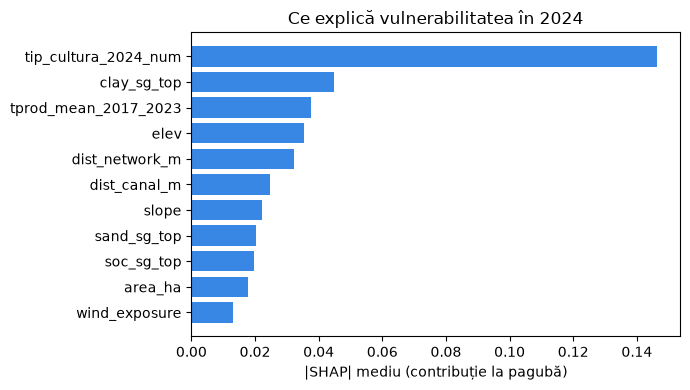

In [7]:
import matplotlib.pyplot as plt
imp = S.abs().mean().sort_values()
imp.index = imp.index.str.replace('shap_', '', regex=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, color='#3987e5')
ax.set_xlabel('|SHAP| mediu (contribuție la pagubă)')
ax.set_title('Ce explică vulnerabilitatea în 2024')
plt.tight_layout(); plt.savefig(OUT / 'shap_importance.png', dpi=200); plt.show()

In [8]:
if os.path.exists('/content'):     # pe PC comiți normal, din git
    push([OUT / 'vulnerability.parquet', OUT / 'vulnerability.gpkg', OUT / 'shap_importance.png'], 'model vulnerabilitate')